# Numerical Gradiant

## Imports

In [2]:
import os
import gzip
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## TwoLayerNet

In [3]:
class TwoLayerNet():
    def __init__(self,
                 input_size,
                 hidden_size,
                 output_size,
                 weight_init_std=0.01):
        # Initialize weights
        self.params = {}
        self.params['W1'] = weight_init_std * np.random.randn(input_size, hidden_size).astype(np.float32)
        self.params['b1'] = np.zeros(hidden_size, dtype=np.float32)
        self.params['W2'] = weight_init_std * np.random.randn(hidden_size, output_size).astype(np.float32)
        self.params['b2'] = np.zeros(output_size, dtype=np.float32)

    def __str__(self):
        return f'TwoLayerNet({self.params})'

    def sigmoid(self, x):
        result = np.empty_like(x)
        positive = x >= 0
        result[positive] = 1 / (1 + np.exp(-x[positive]))
        exp_x = np.exp(x[~positive])
        result[~positive] = exp_x / (1 + exp_x)
        return result

    def softmax(self, x):
        if x.ndim == 2:
            x = x - np.max(x, axis=1, keepdims=True)
            x = np.exp(x)
            x /= np.sum(x, axis=1, keepdims=True)
        elif x.ndim == 1:
            x = x - np.max(x)
            x = np.exp(x) / np.sum(np.exp(x))
        return x

    def predict(self, x):
        W1, W2 = self.params['W1'], self.params['W2']
        b1, b2 = self.params['b1'], self.params['b2']

        a1 = np.dot(x, W1) + b1
        z1 = self.sigmoid(a1)
        a2 = np.dot(z1, W2) + b2
        y = self.softmax(a2)

        return y

    def cross_entropy_error(self, y, t):
        if y.ndim == 1:
            t = t.reshape(1, t.size)
            y = y.reshape(1, y.size)

        batch_size = y.shape[0]
        return -np.sum(t * np.log(y + 1e-7)) / batch_size

    def loss(self, x, t):
        y = self.predict(x)
        return self.cross_entropy_error(y, t)

    def numerical_gradient(self, x, t):
        loss_W = lambda W: self.loss(x, t)

        grads = {}
        grads['W1'] = self.numerical_gradient_param(loss_W, self.params['W1'])
        grads['b1'] = self.numerical_gradient_param(loss_W, self.params['b1'])
        grads['W2'] = self.numerical_gradient_param(loss_W, self.params['W2'])
        grads['b2'] = self.numerical_gradient_param(loss_W, self.params['b2'])

        return grads

    def numerical_gradient_param(self, f, param):
        h = 1e-4  # 0.0001
        grad = np.zeros_like(param)

        it = np.nditer(param, flags=['multi_index'], op_flags=['readwrite'])
        while not it.finished:
            idx = it.multi_index
            tmp_val = param[idx]
            param[idx] = float(tmp_val) + h
            fxh1 = f(param)  # f(x+h)

            param[idx] = tmp_val - h
            fxh2 = f(param)  # f(x-h)
            grad[idx] = (fxh1 - fxh2) / (2 * h)

            param[idx] = tmp_val  # Restore original value
            it.iternext()

        return grad

    def save_weights(self, filename):
        with open(filename, 'wb') as f:
            pickle.dump(self.params, f)

    def load_weights(self, filename):
        with open(filename, 'rb') as f:
            self.params = pickle.load(f)

## Iris

### Import the dataset

In [4]:
iris_df = pd.read_csv('iris/Iris.csv')

x_iris = iris_df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']].values.astype(np.float32)
y_iris = pd.Categorical(iris_df['Species']).codes.astype(np.int32)

y_iris_one_hot = np.zeros((y_iris.size, y_iris.max() + 1), dtype=np.float32)
y_iris_one_hot[np.arange(y_iris.size), y_iris] = 1

indices = np.random.default_rng(42).permutation(x_iris.shape[0])
train_size = int(x_iris.shape[0] * 0.8)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

print(f'Train indices: {train_indices}')
print(f'Test indices: {test_indices}')

Train indices: [ 70  79 134   3 123 120  81 105 130  33 124   4  24 111 129  25   2  20
 125  85  37 143 126  91   0  87  78  27  82  90  94  56  96 103  52  13
 114  28 131   5  66 116 106 135  12  89  54  68 122  46  50 101 144  45
  86  73   7  18  51 146  72  92  38   8 100  98  21  71  59  65 132 108
  93  26  75 133 139  74  10  88  29  63  55  95  42  17  39 149  53  76
 107  40  80  69 118   1 148 104 119  11 145  84  83  43 128  32  61  57
 115  23 147 121  15  48  60 109   9  62  31 127]
Test indices: [117  16  44 112 138  99 142  67  34  30  58  35  77  49   6 102 137  41
 110  22  19  64  47 113 140  14 141  36  97 136]


### Setup the net and train

Iteration 0, Loss: 1.0923614501953125
Iteration 100, Loss: 1.0944116115570068
Iteration 200, Loss: 1.0899875164031982
Iteration 300, Loss: 1.0096789598464966
Iteration 400, Loss: 0.7330988049507141
Iteration 500, Loss: 0.6318235397338867
Iteration 600, Loss: 0.5425776243209839
Iteration 700, Loss: 0.4791134297847748
Iteration 800, Loss: 0.40111494064331055
Iteration 900, Loss: 0.39455440640449524
Iteration 1000, Loss: 0.3917320966720581
Iteration 1100, Loss: 0.33157843351364136
Iteration 1200, Loss: 0.3158246874809265
Iteration 1300, Loss: 0.2251255214214325
Iteration 1400, Loss: 0.212995707988739
Iteration 1500, Loss: 0.24250391125679016
Iteration 1600, Loss: 0.23805613815784454
Iteration 1700, Loss: 0.16401417553424835
Iteration 1800, Loss: 0.15593132376670837
Iteration 1900, Loss: 0.15535014867782593


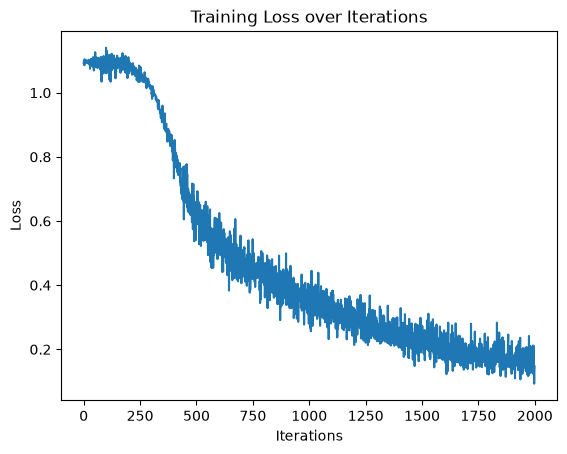

In [5]:
iris_net = TwoLayerNet(input_size=x_iris.shape[1], hidden_size=10, output_size=y_iris_one_hot.shape[1])

iterations = 2000
batch_size = 32
learning_rate = 0.05
iris_train_loss_list = []

for i in range(iterations):
    batch_mask = np.random.choice(train_indices, batch_size)
    x_batch = x_iris[batch_mask]
    y_batch = y_iris_one_hot[batch_mask]

    grads = iris_net.numerical_gradient(x_batch, y_batch)

    for key in iris_net.params:
        iris_net.params[key] -= learning_rate * grads[key]

    loss = iris_net.loss(x_batch, y_batch)
    iris_train_loss_list.append(loss)

    if i % 100 == 0:
        print(f'Iteration {i}, Loss: {loss}')

plt.plot(np.arange(iterations), iris_train_loss_list)
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Training Loss over Iterations')
plt.show()

### Save the model

In [6]:
iris_model_filename = 'novaco_iris_nn_model.pkl'
iris_net.save_weights(iris_model_filename)

### Load in the model and test

In [7]:
test_iris_net = TwoLayerNet(input_size=x_iris.shape[1], hidden_size=10, output_size=y_iris_one_hot.shape[1])
test_iris_net.load_weights(iris_model_filename)

y_test_probs = test_iris_net.predict(x_iris[test_indices])
y_test_preds = np.argmax(y_test_probs, axis=1)
y_actual = y_iris[test_indices]

print(f'Test Predictions: {y_test_preds}')
print(f'Actual Labels: {y_actual}')
print(f'Accuracy: {np.mean(y_test_preds == y_actual) * 100:.2f}%')

correct_count = 0
for i in range(len(y_test_preds)):
    if y_test_preds[i] == y_actual[i]:
        correct_count += 1
    else:
        print(f'Misclassified sample index: {test_indices[i]}, Predicted: {y_test_preds[i]}, Actual: {y_actual[i]}')

accuracy = correct_count / len(y_test_preds)
print(f'Total correct predictions: {correct_count}/{len(y_test_preds)}')

Test Predictions: [2 0 0 2 2 1 2 1 0 0 1 0 1 0 0 2 2 0 2 0 0 1 0 2 2 0 2 0 1 2]
Actual Labels: [2 0 0 2 2 1 2 1 0 0 1 0 1 0 0 2 2 0 2 0 0 1 0 2 2 0 2 0 1 2]
Accuracy: 100.00%
Total correct predictions: 30/30


## MNIST

### Load in the dataset

In [8]:
def load_idx_images(filename):
    with gzip.open(filename, 'rb') as f:
        data = np.frombuffer(f.read(), dtype=np.uint8)

    return data[16:].reshape(-1, 28 * 28).astype(np.float32) / 255.0


def load_idx_labels(filename):
    with gzip.open(filename, 'rb') as f:
        data = np.frombuffer(f.read(), dtype=np.uint8)

    return data[8:].astype(np.int32)


x_train_mnist = load_idx_images('mnist/train-images-idx3-ubyte.gz')
y_train_mnist = load_idx_labels('mnist/train-labels-idx1-ubyte.gz')
x_test_mnist = load_idx_images('mnist/t10k-images-idx3-ubyte.gz')
y_test_mnist = load_idx_labels('mnist/t10k-labels-idx1-ubyte.gz')

print(x_train_mnist.shape, y_train_mnist.shape)
print(x_test_mnist.shape, y_test_mnist.shape)


(60000, 784) (60000,)
(10000, 784) (10000,)


### Setup and train the model

MNIST Iteration 0, Loss: 2.2977089881896973
MNIST Iteration 10, Loss: 2.2859299182891846
MNIST Iteration 20, Loss: 2.285372734069824
MNIST Iteration 30, Loss: 2.2768757343292236
MNIST Iteration 40, Loss: 2.2965569496154785
MNIST Iteration 50, Loss: 2.2636568546295166
MNIST Iteration 60, Loss: 2.296029567718506
MNIST Iteration 70, Loss: 2.294276237487793
MNIST Iteration 80, Loss: 2.2923102378845215
MNIST Iteration 90, Loss: 2.2557895183563232
MNIST Iteration 100, Loss: 2.2638649940490723
MNIST Iteration 110, Loss: 2.267185688018799
MNIST Iteration 120, Loss: 2.2674570083618164
MNIST Iteration 130, Loss: 2.2576487064361572
MNIST Iteration 140, Loss: 2.248284339904785
MNIST Iteration 150, Loss: 2.225861072540283
MNIST Iteration 160, Loss: 2.2337605953216553
MNIST Iteration 170, Loss: 2.2160186767578125
MNIST Iteration 180, Loss: 2.2173941135406494
MNIST Iteration 190, Loss: 2.1484081745147705


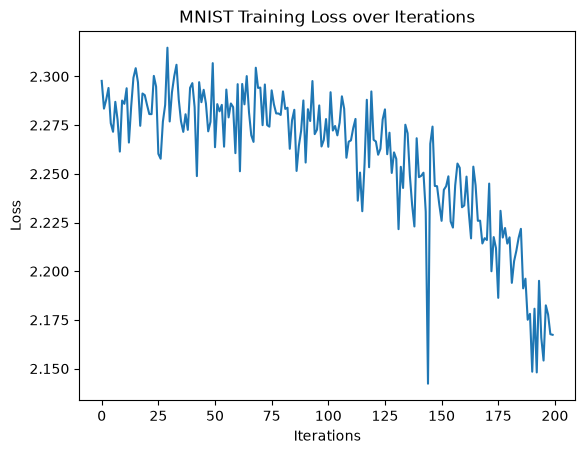

In [11]:
mnist_net = TwoLayerNet(input_size=x_train_mnist.shape[1], hidden_size=50, output_size=10)

iterations_mnist = 200
batch_size_mnist = 64
learning_rate_mnist = 0.1
mnist_loss_list = []

for i in range(iterations_mnist):
    batch_mask = np.random.choice(x_train_mnist.shape[0], batch_size_mnist)
    x_batch = x_train_mnist[batch_mask]
    y_batch = np.zeros((batch_size_mnist, 10), dtype=np.float32)
    y_batch[np.arange(batch_size_mnist), y_train_mnist[batch_mask]] = 1

    grads = mnist_net.numerical_gradient(x_batch, y_batch)


    for key in mnist_net.params:
        mnist_net.params[key] -= learning_rate_mnist * grads[key]

    loss = mnist_net.loss(x_batch, y_batch)
    mnist_loss_list.append(loss)

    if i % 10 == 0:
        print(f'MNIST Iteration {i}, Loss: {loss}')

plt.plot(np.arange(iterations_mnist), mnist_loss_list)
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('MNIST Training Loss over Iterations')
plt.show()

### Save off the model

In [12]:
mnist_model_filename = 'novaco_mnist_nn_model.pkl'
mnist_net.save_weights(mnist_model_filename)

### Load in the model

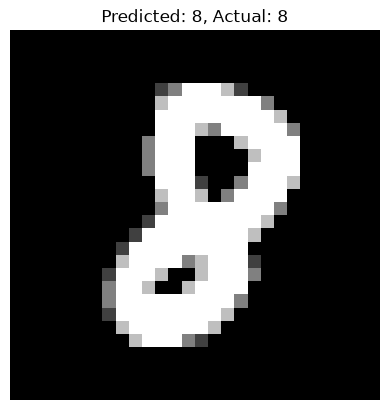

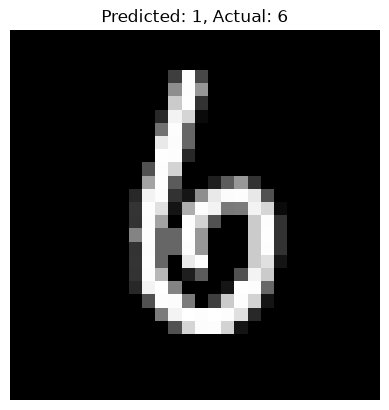

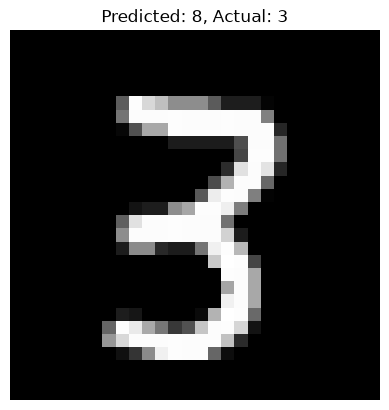

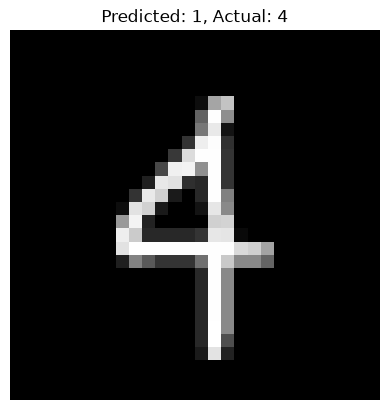

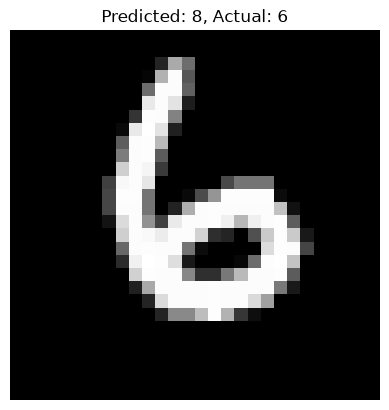

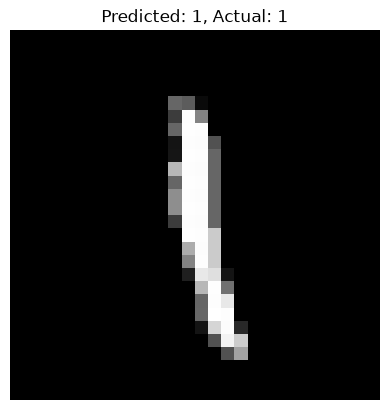

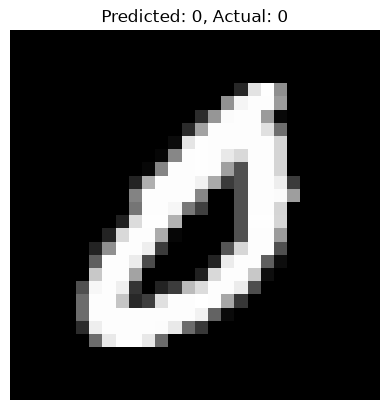

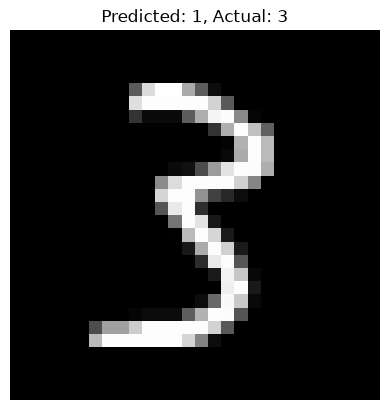

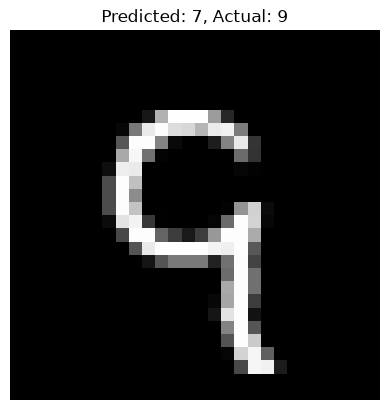

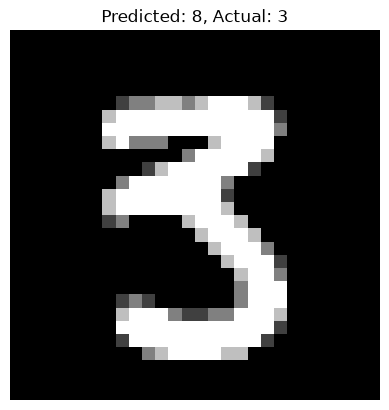

In [13]:
test_mnist_net = TwoLayerNet(input_size=x_train_mnist.shape[1], hidden_size=50, output_size=10)
test_mnist_net.load_weights(mnist_model_filename)

sample_indices = np.random.choice(x_test_mnist.shape[0], 10, replace=False)
for idx in sample_indices:
    x_sample = x_test_mnist[idx].reshape(1, -1)
    y_sample_probs = test_mnist_net.predict(x_sample)
    y_sample_pred = np.argmax(y_sample_probs, axis=1)[0]
    y_sample_actual = y_test_mnist[idx]

    plt.imshow(x_sample.reshape(28, 28), cmap='gray')
    plt.title(f'Predicted: {y_sample_pred}, Actual: {y_sample_actual}')
    plt.axis('off')
    plt.show()